<a href="https://colab.research.google.com/github/nandinikakadecs25/Bio-inspired-System/blob/main/Particle_Swarm_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Searching for the absolute minimum number of sensors for 100% coverage...
Testing coverage with 14 sensors... Max Coverage Achieved: 82.43%
Testing coverage with 15 sensors... Max Coverage Achieved: 89.62%
Testing coverage with 16 sensors... Max Coverage Achieved: 90.70%
Testing coverage with 17 sensors... Max Coverage Achieved: 87.43%
Testing coverage with 18 sensors... Max Coverage Achieved: 93.00%
Testing coverage with 19 sensors... Max Coverage Achieved: 92.43%
Testing coverage with 20 sensors... Max Coverage Achieved: 92.66%
Testing coverage with 21 sensors... Max Coverage Achieved: 95.73%
Testing coverage with 22 sensors... Max Coverage Achieved: 97.04%
Testing coverage with 23 sensors... Max Coverage Achieved: 98.23%
Testing coverage with 24 sensors... Max Coverage Achieved: 98.35%
Testing coverage with 25 sensors... Max Coverage Achieved: 98.31%
Testing coverage with 26 sensors... Max Coverage Achieved: 99.35%
Testing coverage with 27 sensors... Max Coverage Achieved: 99.54%
Te

/tmp/ipykernel_922/4208661787.py:114: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  circle = plt.Circle((pos[0], pos[1]), RADIUS, color='g', alpha=0.3, edgecolor='darkgreen')


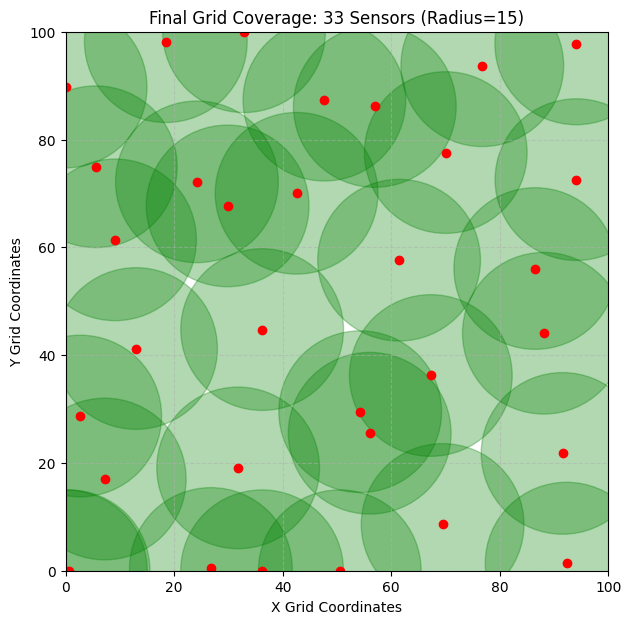

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Problem Configuration ---
GRID_SIZE = 100
RADIUS = 15
RESOLUTION = 2  # Step size for checking grid coverage (lower = more precise)

# Create a dense collection of points representing the full grid
x_range = np.arange(0, GRID_SIZE + 1, RESOLUTION)
y_range = np.arange(0, GRID_SIZE + 1, RESOLUTION)
X_grid, Y_grid = np.meshgrid(x_range, y_range)
GRID_POINTS = np.vstack([X_grid.ravel(), Y_grid.ravel()]).T
TOTAL_POINTS = len(GRID_POINTS)


def compute_coverage(sensor_positions):
    """Calculates what percentage of the grid is covered by the sensors."""
    # sensor_positions shape: (N, 2)
    # Fast distance calculation between all grid points and all sensors
    distances = np.linalg.norm(GRID_POINTS[:, None, :] - sensor_positions[None, :, :], axis=2)
    # Check if a point is within the radius of at least one sensor
    covered_points = np.any(distances <= RADIUS, axis=1)
    return np.sum(covered_points) / TOTAL_POINTS


# --- Particle Swarm Optimization Framework ---
def pso_optimize_placement(num_sensors, max_iter=80, num_particles=30):
    """Optimizes the layout of a fixed number of sensors to maximize coverage."""
    # Dimensions: 2 coordinates (X, Y) per sensor
    dimensions = num_sensors * 2

    # PSO Parameters
    w = 0.72   # Inertia weight
    c1 = 1.49  # Cognitive (personal best) weight
    c2 = 1.49  # Social (global best) weight

    # Initialize particle positions randomly within grid boundaries
    positions = np.random.uniform(0, GRID_SIZE, (num_particles, dimensions))
    velocities = np.random.uniform(-5, 5, (num_particles, dimensions))

    # Tracks the best positions found individually and globally
    p_best_pos = np.copy(positions)
    p_best_cov = np.array([compute_coverage(p.reshape(num_sensors, 2)) for p in positions])

    g_best_idx = np.argmax(p_best_cov)
    g_best_pos = np.copy(p_best_pos[g_best_idx])
    g_best_cov = p_best_cov[g_best_idx]

    # PSO Loop
    for _ in range(max_iter):
        if g_best_cov >= 1.0:  # Early stop if perfect coverage is achieved
            break

        for i in range(num_particles):
            # Generate random coefficients
            r1, r2 = np.random.rand(dimensions), np.random.rand(dimensions)

            # Update Velocity and Position
            velocities[i] = (w * velocities[i] +
                             c1 * r1 * (p_best_pos[i] - positions[i]) +
                             c2 * r2 * (g_best_pos - positions[i]))
            positions[i] += velocities[i]

            # Clamp positions to stay inside the 100x100 grid bounds
            positions[i] = np.clip(positions[i], 0, GRID_SIZE)

            # Evaluate new coverage score
            current_cov = compute_coverage(positions[i].reshape(num_sensors, 2))

            # Update personal best
            if current_cov > p_best_cov[i]:
                p_best_cov[i] = current_cov
                p_best_pos[i] = np.copy(positions[i])

                # Update global best
                if current_cov > g_best_cov:
                    g_best_cov = current_cov
                    g_best_pos = np.copy(positions[i])

    return g_best_pos.reshape(num_sensors, 2), g_best_cov


# --- Search for the MINIMUM Number of Sensors ---
def find_minimum_sensors_for_full_coverage():
    # Start looking from a realistic mathematical baseline count (e.g., 14)
    sensor_count = 14
    print("Searching for the absolute minimum number of sensors for 100% coverage...")

    while True:
        print(f"Testing coverage with {sensor_count} sensors...", end=" ")
        best_layout, coverage_score = pso_optimize_placement(sensor_count)
        print(f"Max Coverage Achieved: {coverage_score * 100:.2f}%")

        # 1.0 translates to 100% full coverage
        if coverage_score >= 1.0:
            print(f"\n🎯 SUCCESS! Found final solution.")
            print(f"Minimum sensors required for full grid coverage: {sensor_count}")
            return best_layout, sensor_count

        sensor_count += 1

# Run the search
final_positions, optimal_count = find_minimum_sensors_for_full_coverage()

# --- Plot the final deployment layout ---
fig, ax = plt.subplots(figsize=(7, 7))
ax.set_xlim(0, GRID_SIZE)
ax.set_ylim(0, GRID_SIZE)
ax.set_title(f"Final Grid Coverage: {optimal_count} Sensors (Radius={RADIUS})")

# Draw sensor radii circles
for pos in final_positions:
    circle = plt.Circle((pos[0], pos[1]), RADIUS, color='g', alpha=0.3, edgecolor='darkgreen')
    ax.add_patch(circle)
    ax.plot(pos[0], pos[1], 'ro')  # Sensor Center point

ax.set_xlabel("X Grid Coordinates")
ax.set_ylabel("Y Grid Coordinates")
ax.grid(True, linestyle='--', alpha=0.5)
plt.show()
